# Create Dataset

# Train

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

# หาโฟลเดอร์ที่มี train / valid / test อยู่ใน Input
candidates = [
    p.parent for p in Path("/kaggle/input").rglob("train")
    if p.is_dir()
    and (p.parent / "valid").is_dir()
    and (p.parent / "test").is_dir()
]
assert candidates, "ไม่พบโฟลเดอร์ที่มี train/valid/test ใน /kaggle/input (เช็กแท็บ Input)"

DATA_DIR = candidates[0]

OUTPUT_DIR = Path("/kaggle/working/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset :", DATA_DIR)
print("Output  :", OUTPUT_DIR)
print("TensorFlow:", tf.__version__)
print("GPUs    :", tf.config.list_physical_devices("GPU"))

Dataset : /kaggle/input/datasets/assanaimuangrod/dataset1/DIV2K_Restoration
Output  : /kaggle/working/models
TensorFlow: 2.20.0
GPUs    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
strategy = tf.distribute.MirroredStrategy()
print("จำนวน GPU ที่ใช้:", strategy.num_replicas_in_sync)

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
จำนวน GPU ที่ใช้: 2


I0000 00:00:1792445765.261831     612 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792445765.264093     612 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [3]:
BATCH_SIZE = 8 * strategy.num_replicas_in_sync
IMG_SIZE = 128

CATEGORIES = ["noise", "blur", "noise_blur"]

def make_dataset(split, categories=CATEGORIES, shuffle=False):
    input_paths = []
    target_paths = []

    clean_dir = DATA_DIR / split / "clean"

    for category in categories:
        degraded_dir = DATA_DIR / split / category

        files = sorted(degraded_dir.glob("*.png"))
        assert files, f"No images: {degraded_dir}"

        for path in files:
            target = clean_dir / path.name

            if not target.exists():
                raise FileNotFoundError(target)

            input_paths.append(str(path))
            target_paths.append(str(target))

    ds = tf.data.Dataset.from_tensor_slices(
        (input_paths, target_paths)
    )

    if shuffle:
        ds = ds.shuffle(
            len(input_paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_pair(x_path, y_path):
        def read_png(path):
            image = tf.io.decode_png(
                tf.io.read_file(path),
                channels=3
            )
            image = tf.image.convert_image_dtype(
                image, tf.float32
            )
            image = tf.ensure_shape(
                image, [IMG_SIZE, IMG_SIZE, 3]
            )
            return image

        return read_png(x_path), read_png(y_path)

    ds = ds.map(
        load_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("valid")
test_ds = make_dataset("test")

for x, y in train_ds.take(1):
    print("Input:", x.shape)
    print("Target:", y.shape)
    print("Range:", float(tf.reduce_min(x)),
          float(tf.reduce_max(x)))

Input: (16, 128, 128, 3)
Target: (16, 128, 128, 3)
Range: 0.0 1.0


**เเก้ตรงนี้ model**

In [4]:
from tensorflow.keras import layers, Model

def build_plain_cnn(num_layers=8, filters=64):
    inputs = layers.Input(shape=(128, 128, 3))

    x = inputs
    for _ in range(num_layers - 1):
        x = layers.Conv2D(
            filters, 3, padding="same",
            kernel_initializer="he_normal"
        )(x)
        x = layers.Activation("relu")(x)

    # เรียนรู้ส่วนแก้ไขเพิ่มเติมจาก Input (เหมือน U-Net)
    residual = layers.Conv2D(
        3, 3, padding="same"
    )(x)

    restored = layers.Add()([inputs, residual])
    outputs = layers.ReLU(max_value=1.0)(restored)

    return Model(inputs, outputs, name="Plain_CNN")


with strategy.scope():
    model = build_plain_cnn()

model.summary()

Model: "Plain_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ conv2d[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ conv2d_2[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ conv2d_3[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 128, 128,  │          0 │ conv2d_4[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 128, 128,  │          0 │ conv2d_5[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 128, 128,  │          0 │ conv2d_6[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │      1,731 │ activation_6[0][… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ input_layer[0][0

 Total params: 225,091 (879.26 KB)

 Trainable params: 225,091 (879.26 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
EPOCHS = 30

with strategy.scope():
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mae",
        metrics=[
            tf.keras.metrics.MeanSquaredError(name="mse")
        ]
    )

checkpoint_path = OUTPUT_DIR / "best_plain_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history_plain = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model:", checkpoint_path)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

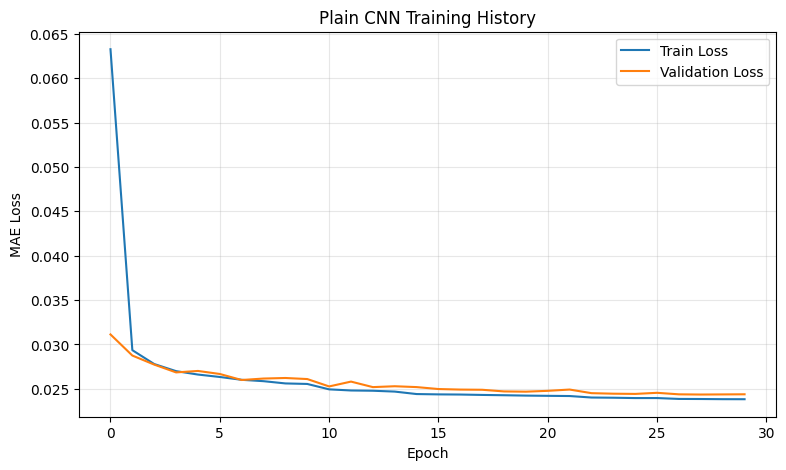

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_plain.history["loss"],
    label="Train Loss"
)

plt.plot(
    history_plain.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE Loss")
plt.title("Plain CNN Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
model = tf.keras.models.load_model(
    str(checkpoint_path)
)

results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    psnr_scores = []
    ssim_scores = []

    for x, y in ds:
        pred = model(x, training=False)
        pred = tf.clip_by_value(pred, 0.0, 1.0)

        psnr = tf.image.psnr(
            y, pred, max_val=1.0
        )
        ssim = tf.image.ssim(
            y, pred, max_val=1.0
        )

        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    results[category] = {
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

for category, scores in results.items():
    print(
        f"{category:12s} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}"
    )

results_plain = results.copy()

noise        | PSNR: 32.78 dB | SSIM: 0.8904
blur         | PSNR: 32.47 dB | SSIM: 0.8373
noise_blur   | PSNR: 28.80 dB | SSIM: 0.7350


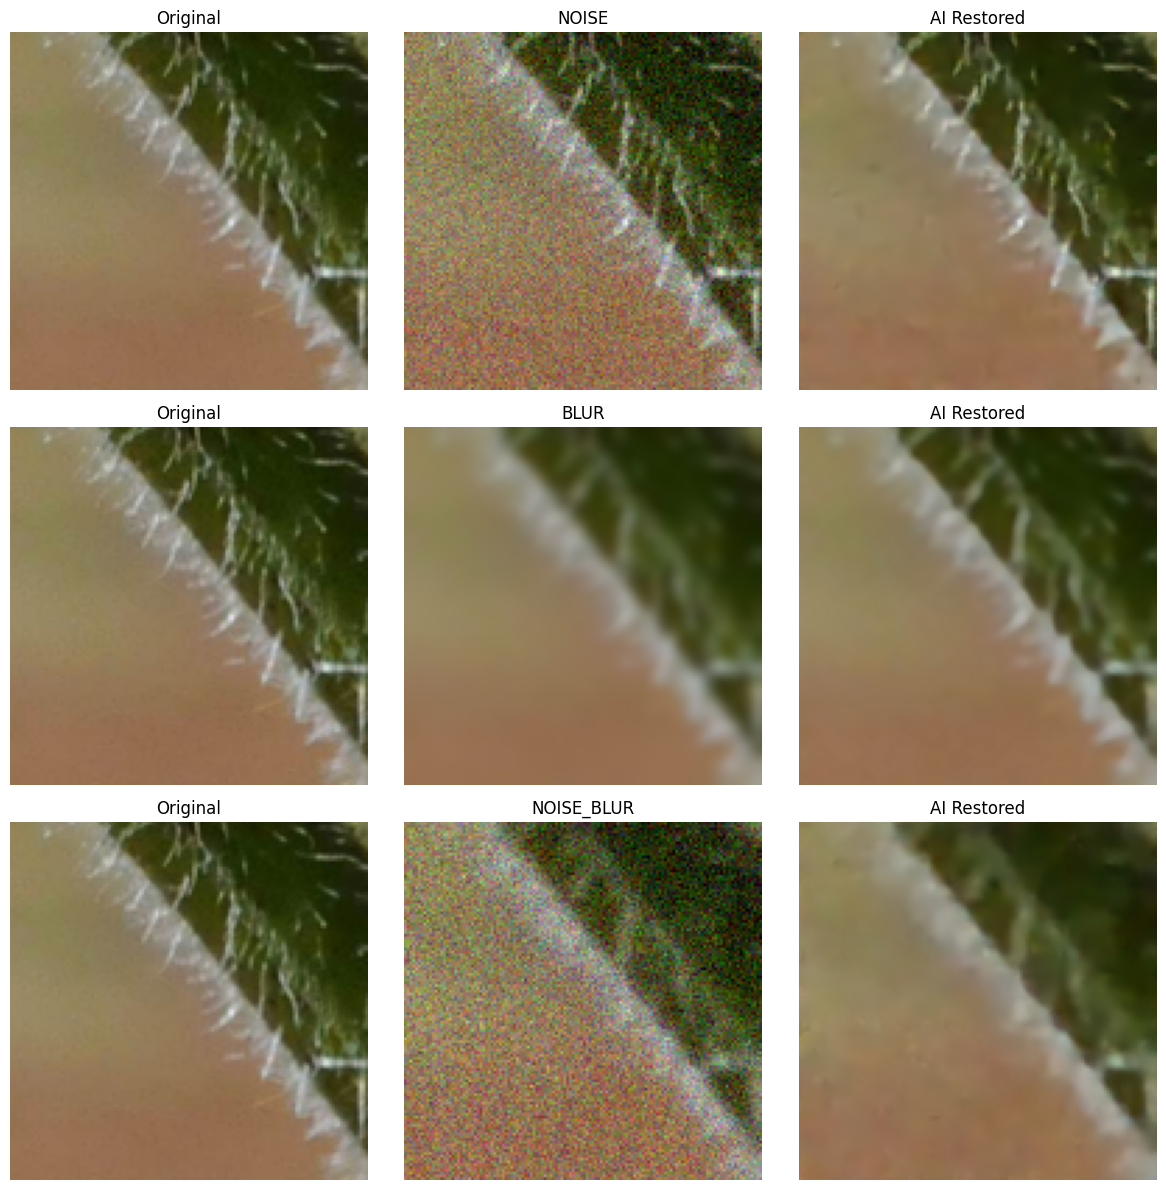

In [8]:
fig, axes = plt.subplots(
    3, 3, figsize=(12, 12)
)

for row, category in enumerate(CATEGORIES):
    ds = make_dataset(
        "test",
        categories=[category]
    )

    x, y = next(iter(ds))

    restored = model(
        x[:1], training=False
    )[0].numpy()

    images = [
        y[0].numpy(),
        x[0].numpy(),
        restored
    ]

    titles = [
        "Original",
        category.upper(),
        "AI Restored"
    ]

    for col, (img, title) in enumerate(zip(images, titles)):
        axes[row, col].imshow(
            np.clip(img, 0, 1)
        )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    str(OUTPUT_DIR / "restoration_results_plain.png"),
    dpi=200
)

plt.show()

In [9]:
model = tf.keras.models.load_model(
    str(checkpoint_path)
)

results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    mae_scores = []
    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    for x, y in ds:
        pred = model(x, training=False)
        pred = tf.clip_by_value(pred, 0.0, 1.0)

        # เฉลี่ยแกนความสูง ความกว้าง และช่องสี ได้หนึ่งค่าต่อภาพ
        error = y - pred

        mae = tf.reduce_mean(
            tf.abs(error), axis=[1, 2, 3]
        )
        mse = tf.reduce_mean(
            tf.square(error), axis=[1, 2, 3]
        )

        psnr = tf.image.psnr(
            y, pred, max_val=1.0
        )
        ssim = tf.image.ssim(
            y, pred, max_val=1.0
        )

        mae_scores.extend(mae.numpy())
        mse_scores.extend(mse.numpy())
        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    results[category] = {
        "MAE": float(np.mean(mae_scores)),
        "MSE": float(np.mean(mse_scores)),
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

for category, scores in results.items():
    print(
        f"{category:12s} | "
        f"MAE: {scores['MAE']:.6f} | "
        f"MSE: {scores['MSE']:.6f} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}"
    )

noise        | MAE: 0.019121 | MSE: 0.000761 | PSNR: 32.78 dB | SSIM: 0.8904
blur         | MAE: 0.023606 | MSE: 0.002195 | PSNR: 32.47 dB | SSIM: 0.8373
noise_blur   | MAE: 0.032431 | MSE: 0.003225 | PSNR: 28.80 dB | SSIM: 0.7350


In [10]:
model.save_weights("model.weights.h5")